# データ並列の実装

100個のデータから、直線の傾きと切片を学習する簡単なモデルを通じて、データ並列の処理を追います。

本来であれば、複数 GPU で行いたい処理ですが、Google Colab では単一 GPU の環境しか使用できないため、CPU 上のシミュレーションを実装します。

同じプロセス内で2つの担当を用意し、データの分割・勾配の平均・パラメータの更新をシミュレーションします。CPU で実行できます。

In [1]:
!pip install -q numpy  # ノイズを含むデータの生成
!pip install -q torch  # 勾配計算とプロセス間通信
!pip install -q matplotlib  # データと学習結果の描画
!pip install -q japanize_matplotlib  # 図の日本語表示

## データとモデル

$y=2x+1$ にノイズを加えた100点を使います。この点群に合う直線 $\hat{y}=ax+b$ の、傾き $a$ と切片 $b$ を学習します。

傾きと切片の初期値から、勾配を計算して1回更新するところまでを実装します。

In [2]:
import numpy as np
import torch

true_a = 2.0
true_b = 1.0
np.random.seed(42)
x_values = np.random.uniform(-5, 5, 100)
y_values = true_a * x_values + true_b + np.random.normal(0, 0.5, 100)

# NumPy で生成したデータを、自動微分に使うテンソルへ変換する
x = torch.tensor(x_values, dtype=torch.float64)
y = torch.tensor(y_values, dtype=torch.float64)
print("データ数:", len(x))
print("先頭5点の x:", x[:5].tolist())
print("先頭5点の y:", y[:5].tolist())

データ数: 100
先頭5点の x: [-1.254598811526375, 4.507143064099161, 2.3199394181140507, 0.986584841970366, -3.439813595575635]
先頭5点の y: [-1.4656740889336646, 9.864782452965388, 5.685759224495852, 1.9793852266402856, -5.989463135070026]


担当の番号を `rank` と呼び、0と1を使います。それぞれ50点ずつ受け持ちます。色を分けて、どちらの担当にもばらつきのある点が渡ることを確認します。

rank 0: 50点
rank 1: 50点


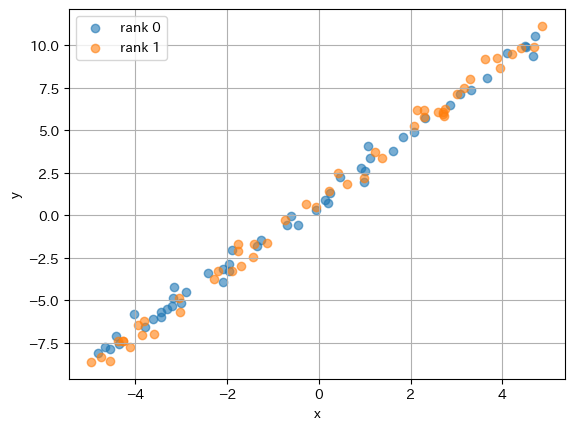

In [3]:
import matplotlib.pyplot as plt
import japanize_matplotlib  # 図の日本語表示

# 先頭50点と残り50点に分け、正解も同じ位置で分ける
local_x = [x[:50], x[50:]]
local_y = [y[:50], y[50:]]
for rank in range(2):
    print(f"rank {rank}: {len(local_x[rank])}点")
    plt.scatter(
        local_x[rank].numpy(), local_y[rank].numpy(), alpha=0.6, label=f"rank {rank}"
    )
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.show()

### 初期値

$a,b$ を1つのテンソルにまとめます。`parameters[0]` が傾き、`parameters[1]` が切片です。各担当は、同じ初期値のコピーを持ちます。

In [4]:
np.random.seed(42)
initial_parameters = torch.tensor(
    [np.random.randn(), np.random.randn()], dtype=torch.float64
)

# 別々に更新できるコピーを用意し、a と b の勾配を計算できるようにする
local_parameters = [initial_parameters.clone().requires_grad_() for _ in range(2)]
print("初期値 [a, b]:", initial_parameters.tolist())
for rank, parameters in enumerate(local_parameters):
    print(f"rank {rank}: a={parameters[0].item():.6f}, b={parameters[1].item():.6f}")

初期値 [a, b]: [0.4967141530112327, -0.13826430117118466]
rank 0: a=0.496714, b=-0.138264
rank 1: a=0.496714, b=-0.138264


## 勾配の平均とパラメータの更新

損失は、予測とデータの差の2乗を平均した値（MSE）です。

$$L=\frac{1}{n}\sum_i(ax_i+b-y_i)^2$$

各担当は、自分の50点だけで損失と勾配を計算します。

In [5]:
local_gradients = []
for rank, parameters in enumerate(local_parameters):
    parameters.grad = None  # 前の勾配を消す
    prediction = parameters[0] * local_x[rank] + parameters[1]
    loss = ((prediction - local_y[rank]) ** 2).mean()

    print(f"rank {rank}: 損失={loss.item():.6f}")
    loss.backward()  # parameters.grad に [a の勾配, b の勾配] を保存する
    local_gradients.append(parameters.grad.detach().clone())
    print(f"rank {rank}: 勾配={parameters.grad.tolist()}")
    print("-----------")

rank 0: 損失=17.164081
rank 0: 勾配=[-23.1305160470106, -0.6698731698603824]
-----------
rank 1: 損失=22.587682
rank 1: 勾配=[-27.925587647533646, -2.0879486565990826]
-----------


担当するデータが異なるので、勾配も異なります。傾きと切片それぞれの勾配を平均します。

In [6]:
# 2行（担当）× 2列（a, b）の勾配を、列ごとに平均する
average_gradient = torch.stack(local_gradients).mean(dim=0)
print("平均した勾配 [a, b]:", average_gradient.tolist())

平均した勾配 [a, b]: [-25.528051847272124, -1.3789109132297326]


### 全体バッチとの比較

同じ初期値から、100点まとめて損失と勾配を計算します。50点ずつで求めた勾配の平均と一致するでしょうか。

In [7]:
reference_parameters = initial_parameters.clone().requires_grad_()
reference_prediction = reference_parameters[0] * x + reference_parameters[1]
reference_loss = ((reference_prediction - y) ** 2).mean()
reference_loss.backward()
print("100点まとめた勾配:", reference_parameters.grad.tolist())
print("50点ずつの勾配の平均:", average_gradient.tolist())

100点まとめた勾配: [-25.52805184727212, -1.3789109132297326]
50点ずつの勾配の平均: [-25.528051847272124, -1.3789109132297326]


小数の丸め誤差を除き、勾配が一致しました。各担当の勾配を、平均値で上書きします。

In [8]:
for rank, parameters in enumerate(local_parameters):
    before = parameters.grad.clone()
    parameters.grad.copy_(average_gradient)  # a と b の勾配を両方とも置き換える
    print(f"rank {rank}: {before.tolist()} → {parameters.grad.tolist()}")

rank 0: [-23.1305160470106, -0.6698731698603824] → [-25.528051847272124, -1.3789109132297326]
rank 1: [-27.925587647533646, -2.0879486565990826] → [-25.528051847272124, -1.3789109132297326]


SGD で $a,b$ それぞれから「学習率 × 勾配」を引きます。

In [9]:
learning_rate = 0.01

for rank, parameters in enumerate(local_parameters):
    optimizer = torch.optim.SGD([parameters], lr=learning_rate)
    optimizer.step()
    print(f"rank {rank}: a={parameters[0].item():.6f}, b={parameters[1].item():.6f}")

rank 0: a=0.751995, b=-0.124475
rank 1: a=0.751995, b=-0.124475


これを繰り返すことで、データ並列を使いつつ、学習を進めていきます。

## まとめ

データ並列の大まかな流れは以下の通りです。

- モデルのパラメータのコピーを異なるプロセス上に保持する
- データを分割し、それぞれのプロセスで勾配を計算する
- 各プロセスの勾配を平均し、それらを使って、各プロセスのパラメータを更新する

多くの場合は、フレームワークで、簡単にデータ並列を行うための実装が提供されているはずです。
参考: [PyTorch の DDP](https://docs.pytorch.org/docs/stable/generated/torch.nn.parallel.DistributedDataParallel.html)